In [8]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    mean_squared_error,
    r2_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# Load as Excel first, fallback to CSV
try:
  df = pd.read_excel("Maths.csv")
except Exception:
  try:
    df = pd.read_csv("Maths.csv", sep=";")
  except Exception:
    df = pd.read_csv("Maths.csv", sep=",")

print(f"Loaded successfully: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded successfully: 397 rows, 33 columns


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:
print("Missing values total:", df.isnull().sum().sum())

# Binary classification target: Pass (G3 >= 10) vs Fail (G3 < 10)
df['passed'] = (df['G3'] >= 10).astype(int)

pass_count = df['passed'].value_counts()
print(f"Overall Pass Rate: {df['passed'].mean() * 100:.2f}%")
print(f"Passed: {pass_count.get(1, 0)} | Failed: {pass_count.get(0, 0)}")

Missing values total: 0
Overall Pass Rate: 66.75%
Passed: 265 | Failed: 132


/tmp/ipykernel_3152/4083106250.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='studytime', y='G3', data=df, ax=axes[0, 1], palette="Blues")
/tmp/ipykernel_3152/4083106250.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs'])
/tmp/ipykernel_3152/4083106250.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Walc', y='failures', data=df, ax=axes[1, 0], palette="Reds")


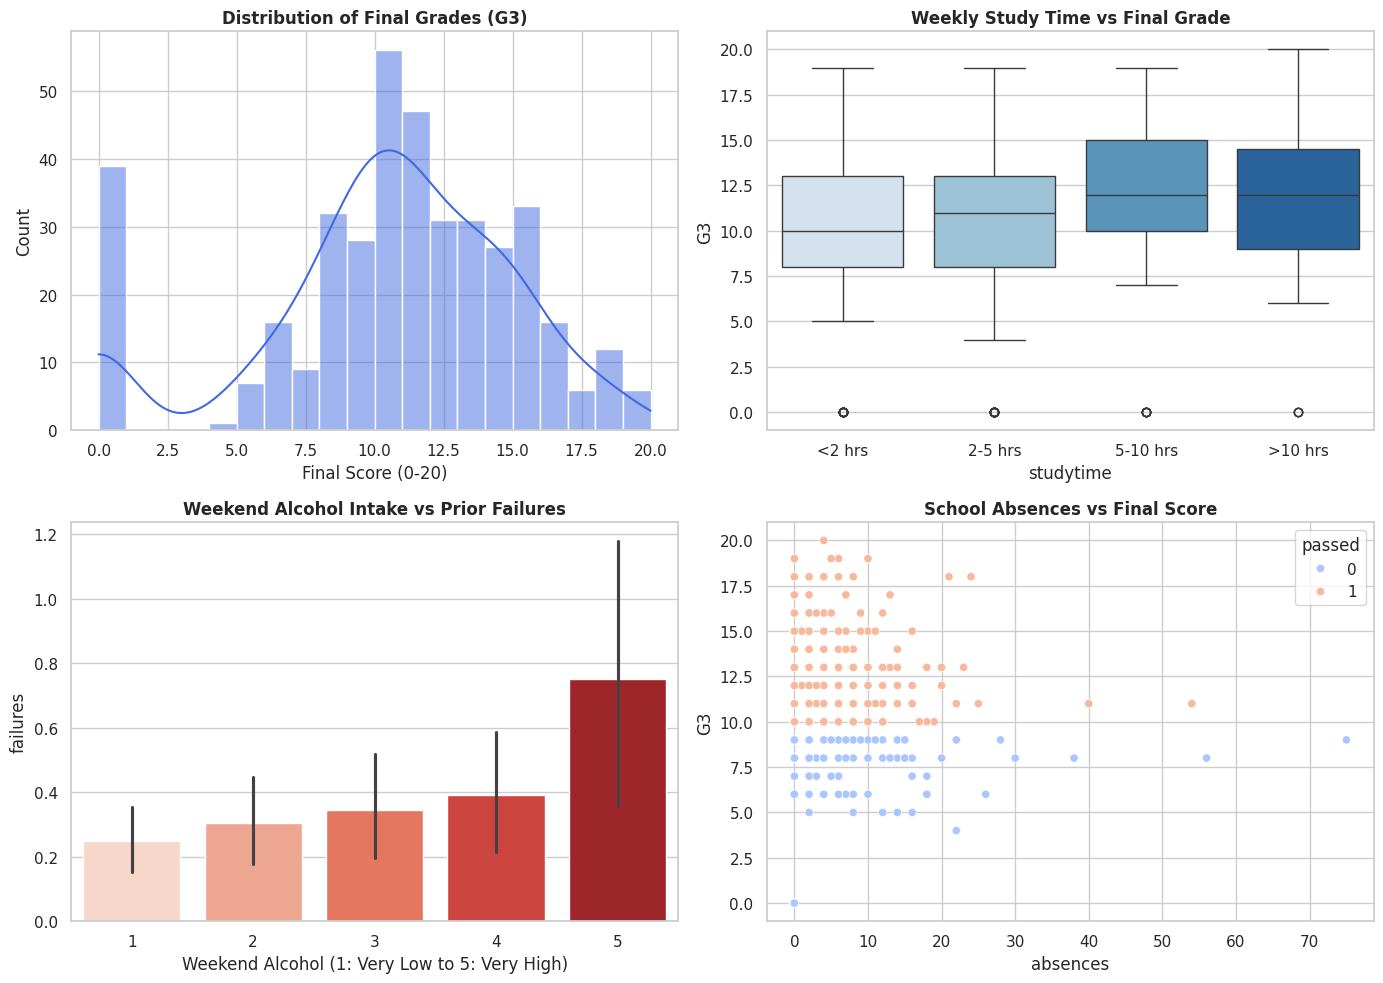

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Final Grade Distribution
sns.histplot(df['G3'], bins=20, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title("Distribution of Final Grades (G3)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Final Score (0-20)")

# 2. Weekly Study Time vs Final Grade
sns.boxplot(x='studytime', y='G3', data=df, ax=axes[0, 1], palette="Blues")
axes[0, 1].set_title("Weekly Study Time vs Final Grade", fontsize=12, fontweight='bold')
axes[0, 1].set_xticklabels(['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs'])

# 3. Weekend Alcohol Intake vs Historic Failures
sns.barplot(x='Walc', y='failures', data=df, ax=axes[1, 0], palette="Reds")
axes[1, 0].set_title("Weekend Alcohol Intake vs Prior Failures", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Weekend Alcohol (1: Very Low to 5: Very High)")

# 4. Absences vs Final Grade
sns.scatterplot(x='absences', y='G3', hue='passed', data=df, ax=axes[1, 1], palette="coolwarm")
axes[1, 1].set_title("School Absences vs Final Score", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [14]:
# Separate features and target variables
X = df.drop(columns=['G3', 'passed'])
y_clf = df['passed']
y_reg = df['G3']

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Preprocessing transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

# Train/Test splits
X_train, X_test, y_train_clf, y_test_clf = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)
_, _, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

# 1. Classification Model: Random Forest
clf_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42))
])
clf_pipeline.fit(X_train, y_train_clf)
y_pred_clf = clf_pipeline.predict(X_test)
y_prob_clf = clf_pipeline.predict_proba(X_test)[:, 1]

print("=== CLASSIFICATION REPORT (Predicting Pass/Fail) ===")
print(classification_report(y_test_clf, y_pred_clf, target_names=['Fail', 'Pass']))
print(f"ROC-AUC Score: {roc_auc_score(y_test_clf, y_prob_clf):.4f}")

# 2. Regression Model: Ridge Regression
reg_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', Ridge(alpha=1.0))
])
reg_pipeline.fit(X_train, y_train_reg)
y_pred_reg = reg_pipeline.predict(X_test)

print("\n=== REGRESSION EVALUATION (Predicting Score G3) ===")
print(f"R² Score: {r2_score(y_test_reg, y_pred_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)):.4f}")

=== CLASSIFICATION REPORT (Predicting Pass/Fail) ===
              precision    recall  f1-score   support

        Fail       0.77      0.89      0.83        27
        Pass       0.94      0.87      0.90        53

    accuracy                           0.88        80
   macro avg       0.86      0.88      0.86        80
weighted avg       0.88      0.88      0.88        80

ROC-AUC Score: 0.9336

=== REGRESSION EVALUATION (Predicting Score G3) ===
R² Score: -0.0121
RMSE: 4.5156


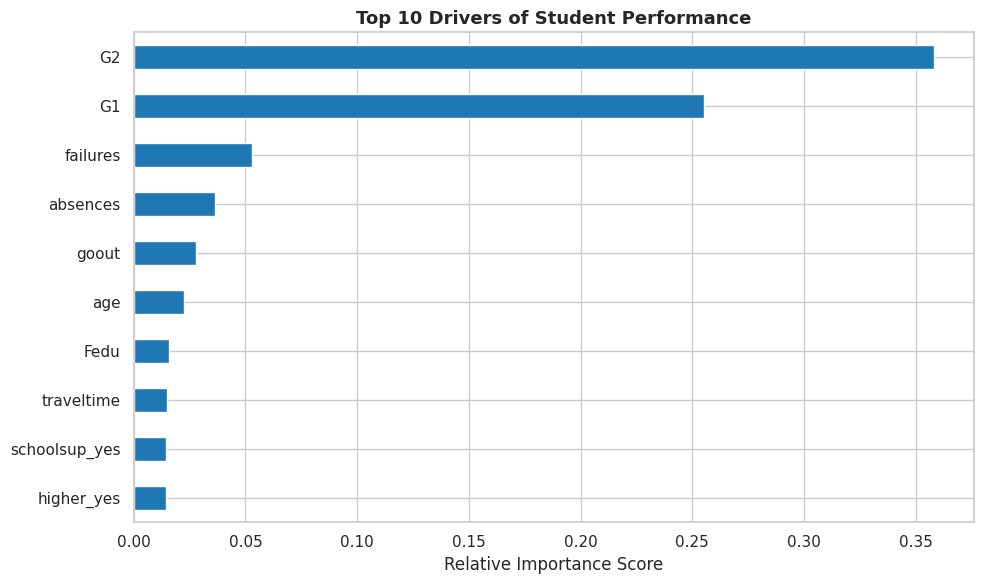

In [16]:
# Extract feature importances from Random Forest model
rf_model = clf_pipeline.named_steps['model']
encoded_cats = list(clf_pipeline.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(categorical_cols))
all_features = numeric_cols + encoded_cats

importances = pd.Series(rf_model.feature_importances_, index=all_features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='#1f77b4')
plt.title("Top 10 Drivers of Student Performance", fontsize=13, fontweight='bold')
plt.xlabel("Relative Importance Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()